# LAB 6: Implementation of Decision Tree Classifier for Multi-Class Credit Risk Assessment

## 1. Context & Problem Statement
Decision trees are interpretable, auditable, non-parametric models that split data with hierarchical rules and need no feature scaling. Given `Debt_to_Income_Ratio, Credit_Score, Annual_Income, Missed_Payments_Count`, predict `Credit_Risk_Rating` (0 = Low, 1 = Moderate, 2 = High).

**Objectives**
- Understand optimal splitting with **Gini impurity** and **entropy / information gain**.
- Control overfitting with **pre-pruning** (`max_depth`, `min_samples_split`, `min_samples_leaf`) and **cost-complexity pruning** (`ccp_alpha`).
- Extract human-readable rules and evaluate with confusion matrix, precision / recall / F1 and ROC-AUC (OvR).

$$Gini(t)=1-\sum_i p_i^2 \qquad Entropy(t)=-\sum_i p_i\log_2 p_i \qquad IG=Entropy(parent)-\sum \tfrac{N_{child}}{N_{parent}}Entropy(child)$$

## 2. Implementation
### Step 1: Generate the synthetic dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score

sns.set_theme(style="whitegrid")
np.random.seed(42)
n_samples = 1000
data = {
    "Debt_to_Income_Ratio": np.random.uniform(0.1, 0.8, n_samples),
    "Credit_Score": np.random.randint(300, 850, n_samples),
    "Annual_Income": np.random.uniform(20000, 150000, n_samples),
    "Missed_Payments_Count": np.random.randint(0, 10, n_samples),
}
df = pd.DataFrame(data)
risk_index = (df["Debt_to_Income_Ratio"] * 2.5) + (df["Missed_Payments_Count"] * 0.4) - (df["Credit_Score"] / 300.0)
df["Credit_Risk_Rating"] = pd.qcut(risk_index, q=3, labels=[0, 1, 2]).astype(int)

display(df.head())
print(df["Credit_Risk_Rating"].value_counts().sort_index())

,Debt_to_Income_Ratio,Credit_Score,Annual_Income,Missed_Payments_Count,Credit_Risk_Rating
0,0.362178,311,97917.965536,1,0
1,0.765500,617,98278.933727,8,2
2,0.612396,515,22981.265465,0,0
3,0.519061,638,61874.040550,9,2
4,0.209213,380,102743.784636,5,1


Credit_Risk_Rating
0    334
1    333
2    333
Name: count, dtype: int64


### Step 2: Stratified train-test split (80:20)

In [2]:
feature_cols = ["Debt_to_Income_Ratio", "Credit_Score", "Annual_Income", "Missed_Payments_Count"]
X = df[feature_cols]
y = df["Credit_Risk_Rating"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (800, 4)  Test: (200, 4)


### Step 3: Train a pre-pruned Decision Tree (Gini)

In [3]:
dt_model = DecisionTreeClassifier(criterion="gini", max_depth=4, min_samples_split=10, min_samples_leaf=5, random_state=42)
dt_model.fit(X_train, y_train)
print("Depth:", dt_model.get_depth(), "| leaves:", dt_model.get_n_leaves())

Depth: 4 | leaves: 16


### Step 4: Prediction and evaluation

In [4]:
names = ["Low Risk", "Moderate Risk", "High Risk"]
y_pred = dt_model.predict(X_test)
y_probs = dt_model.predict_proba(X_test)
cm = confusion_matrix(y_test, y_pred)

print("Train accuracy:", round(dt_model.score(X_train, y_train), 4), "| Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\n--- Confusion Matrix ---"); print(cm)
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=names))
print(f"ROC-AUC (OvR): {roc_auc_score(y_test, y_probs, multi_class='ovr'):.4f}")

Train accuracy: 0.8825 | Test accuracy: 0.84

--- Confusion Matrix ---
[[58  9  0]
 [11 54  2]
 [ 0 10 56]]

--- Classification Report ---
               precision    recall  f1-score   support

     Low Risk       0.84      0.87      0.85        67
Moderate Risk       0.74      0.81      0.77        67
    High Risk       0.97      0.85      0.90        66

     accuracy                           0.84       200
    macro avg       0.85      0.84      0.84       200
 weighted avg       0.85      0.84      0.84       200

ROC-AUC (OvR): 0.9407


### Step 5: Feature importance analysis

--- Feature Importances ---
Missed_Payments_Count    0.5557
Debt_to_Income_Ratio     0.2397
Credit_Score             0.2046
Annual_Income            0.0000
dtype: float64


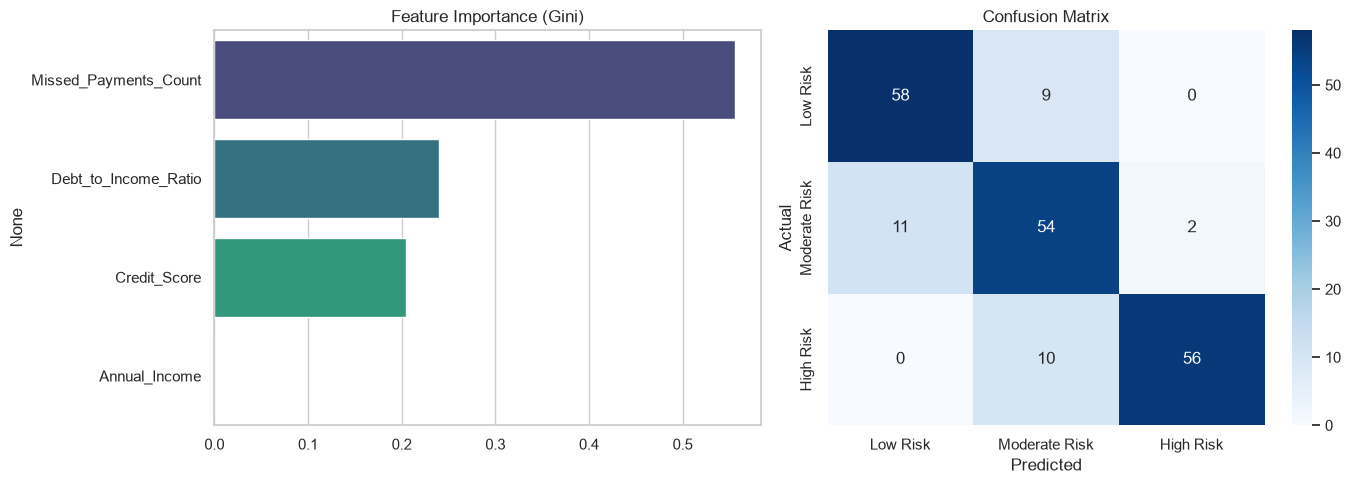

In [5]:
feature_imp = pd.Series(dt_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("--- Feature Importances ---"); print(feature_imp.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=feature_imp.values, y=feature_imp.index, hue=feature_imp.index, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Feature Importance (Gini)")
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=axes[1])
axes[1].set_title("Confusion Matrix"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
plt.tight_layout(); plt.show()

### Step 6: Decision rules and tree diagram

--- Decision Tree Rules ---
|--- Missed_Payments_Count <= 4.50
|   |--- Credit_Score <= 519.50
|   |   |--- Missed_Payments_Count <= 1.50
|   |   |   |--- Debt_to_Income_Ratio <= 0.55
|   |   |   |   |--- class: 0
|   |   |   |--- Debt_to_Income_Ratio >  0.55
|   |   |   |   |--- class: 1
|   |   |--- Missed_Payments_Count >  1.50
|   |   |   |--- Debt_to_Income_Ratio <= 0.25
|   |   |   |   |--- class: 0
|   |   |   |--- Debt_to_Income_Ratio >  0.25
|   |   |   |   |--- class: 1
|   |--- Credit_Score >  519.50
|   |   |--- Missed_Payments_Count <= 2.50
|   |   |   |--- Credit_Score <= 593.00
|   |   |   |   |--- class: 0
|   |   |   |--- Credit_Score >  593.00
|   |   |   |   |--- class: 0
|   |   |--- Missed_Payments_Count >  2.50
|   |   |   |--- Debt_to_Income_Ratio <= 0.43
|   |   |   |   |--- class: 0
|   |   |   |--- Debt_to_Income_Ratio >  0.43
|   |   |   |   |--- class: 1
|--- Missed_Payments_Count >  4.50
|   |--- Missed_Payments_Count <= 6.50
|   |   |--- Credit_Score <= 50

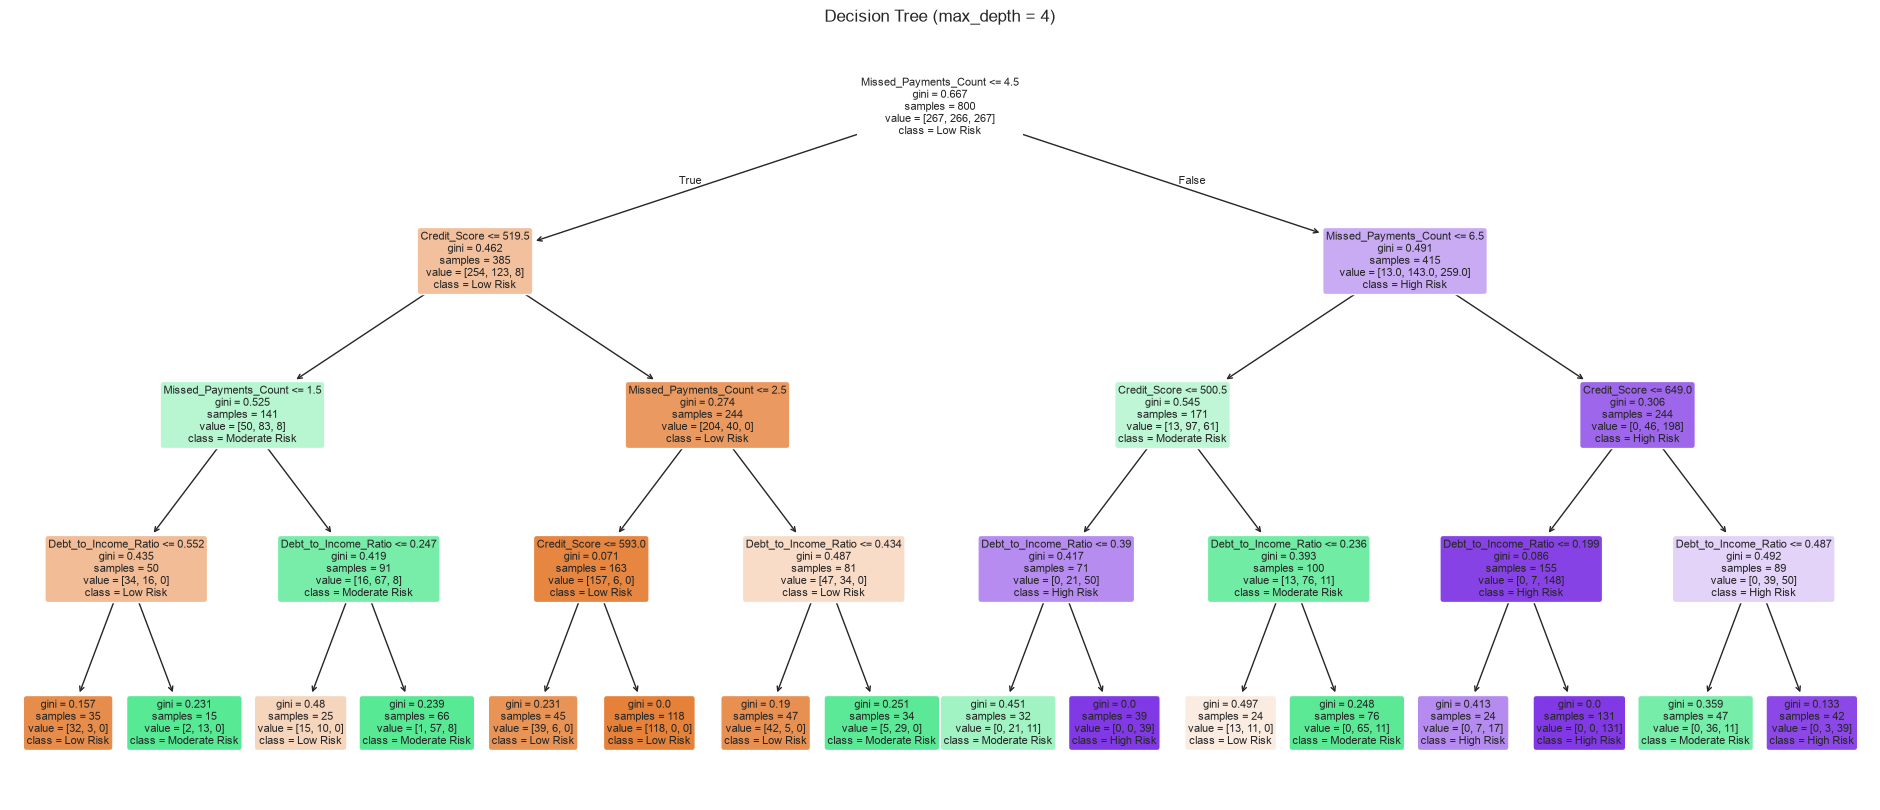

In [6]:
print("--- Decision Tree Rules ---")
print(export_text(dt_model, feature_names=list(X.columns))[:1500])

plt.figure(figsize=(24, 10))
plot_tree(dt_model, feature_names=X.columns, class_names=names, filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree (max_depth = 4)"); plt.show()

### Step 7: Gini vs Entropy and depth (pre-pruning) analysis

,Criterion,Train acc,Test acc,CV acc (5-fold)
0,gini,0.8825,0.840,0.8462
1,entropy,0.8775,0.855,0.8225


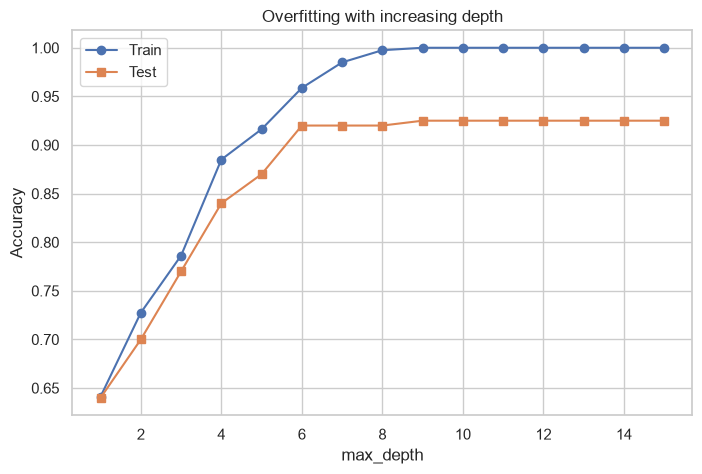

In [7]:
rows = []
for crit in ["gini", "entropy"]:
    m = DecisionTreeClassifier(criterion=crit, max_depth=4, min_samples_split=10, min_samples_leaf=5, random_state=42).fit(X_train, y_train)
    rows.append({"Criterion": crit, "Train acc": m.score(X_train, y_train), "Test acc": m.score(X_test, y_test),
                 "CV acc (5-fold)": cross_val_score(m, X_train, y_train, cv=5).mean()})
display(pd.DataFrame(rows).round(4))

depths = range(1, 16)
tr, te = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    tr.append(m.score(X_train, y_train)); te.append(m.score(X_test, y_test))
plt.figure(figsize=(8, 5)); plt.plot(depths, tr, "o-", label="Train"); plt.plot(depths, te, "s-", label="Test")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.title("Overfitting with increasing depth"); plt.legend(); plt.show()

### Step 8: Cost-complexity pruning (`ccp_alpha`) chosen by cross-validation

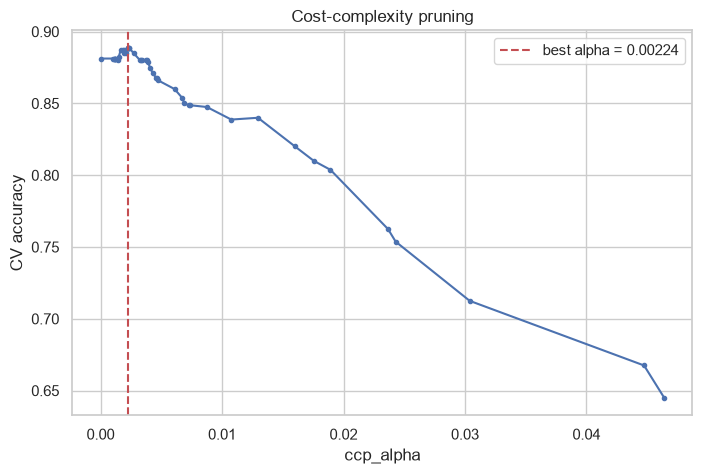

Best ccp_alpha: 0.00224
Pre-pruned tree : depth=4, leaves=16, test acc=0.8400
CCP-pruned tree : depth=7, leaves=48, test acc=0.9200


In [8]:
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(path.ccp_alphas[:-1])
alphas = alphas[:: max(1, len(alphas) // 40)]            # keep the loop fast

cv_means = [cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=42), X_train, y_train, cv=5).mean() for a in alphas]
best_alpha = alphas[int(np.argmax(cv_means))]
pruned = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(8, 5)); plt.plot(alphas, cv_means, marker="o", ms=3)
plt.axvline(best_alpha, color="r", ls="--", label=f"best alpha = {best_alpha:.5f}")
plt.xlabel("ccp_alpha"); plt.ylabel("CV accuracy"); plt.title("Cost-complexity pruning"); plt.legend(); plt.show()

print(f"Best ccp_alpha: {best_alpha:.5f}")
print(f"Pre-pruned tree : depth={dt_model.get_depth()}, leaves={dt_model.get_n_leaves()}, test acc={dt_model.score(X_test, y_test):.4f}")
print(f"CCP-pruned tree : depth={pruned.get_depth()}, leaves={pruned.get_n_leaves()}, test acc={pruned.score(X_test, y_test):.4f}")

## 3. Summary
| Component | Specification |
|---|---|
| Model | Decision Tree Classifier |
| Target | `Credit_Risk_Rating` (0 = Low, 1 = Moderate, 2 = High) |
| Features | Debt_to_Income_Ratio, Credit_Score, Annual_Income, Missed_Payments_Count |
| Splitting criteria | Gini impurity / entropy |
| Regularisation | Pre-pruning (`max_depth`, `min_samples_split`, `min_samples_leaf`) and `ccp_alpha` |
| Interpretability | `export_text`, `plot_tree`, feature importances |
| Metrics | Accuracy, precision, recall, F1, confusion matrix, ROC-AUC (OvR) |

## 4. Conclusion
- The risk label was generated from Debt-to-Income ratio, Missed payments and Credit score (not Annual_Income), and the tree's feature importances recover exactly this - `Annual_Income` receives almost no importance.
- Without a depth limit the tree memorises the training set (train accuracy 1.0) while test accuracy stops improving (see the depth plot).
- The depth-4 pre-pruned tree is small and easy to read but slightly underfits (about 84% test accuracy). Cost-complexity pruning with `ccp_alpha` chosen by cross-validation grows a deeper tree that is still pruned back from the full tree and scores higher on the test set (about 92%), so the best regularised tree is not necessarily the shallowest one.
- Gini and entropy give similar results here; the extracted rules make every prediction fully auditable.